# Lab: SQL-to-Python Cloud Notebook Workflow

## Scenario: Support Operations Resolution Time

You are working as a junior data analyst for a software company's customer support operations team. The support operations manager asks:

> Can you help us understand which support ticket categories took the longest to resolve for tickets created during Q1 2026, from January 1, 2026, through March 31, 2026, and whether any team or category may need closer review?

This notebook uses the provided `support_operations.db` database and follows **Identify → Assemble → Execute → Verify**.

## Platform Setup

**Platform used: Google Colab.** `support_operations.db` is stored in **Google Drive** at `MyDrive/support_operations.db`, so it persists when the Colab runtime resets. The connection cell detects the environment:

- **In Colab**, it mounts Google Drive and reads the database from Drive.
- **Anywhere else** (local Jupyter, Posit Cloud, SageMaker Studio Lab), it reads `support_operations.db` from the notebook's folder.

The same notebook therefore runs top to bottom on any platform without edits.

## Step 1: Clarify the Support Operations Question (Identify)

### Planning Note

**What question am I trying to answer?**
For support tickets **created between January 1 and March 31, 2026** that reached a completed status, which ticket categories (and category–team combinations) took the longest on average to resolve, and does any team or category stand out enough to deserve a closer review?

**What does "took the longest to resolve" mean here?**
Resolution time for one ticket = `resolved_date − created_date`, in days. "Took the longest" means the highest **average** resolution time for a group. Because an average can be pulled up by one extreme ticket, I also check the median and the slowest single ticket before calling a group slow.

**What data do I need?**
- Ticket records: ID, created date, resolved date, status, category ID, team ID
- Readable category names and team names (in separate lookup tables)
- Optionally, the category's standard (benchmark) resolution time, for context

**What output would be useful to the manager?**
A ranked table of category–team combinations with ticket count and average days, a chart of the slowest combinations, and a short written explanation. The explanation should say which results rest on enough tickets to trust, and which deserve a closer look.

**What checks will help me verify the result?**
- Confirm the date filter keeps only Q1 2026 created dates
- Confirm only `Resolved`/`Closed` tickets with a resolved date are included
- Count completed tickets dropped for a missing resolved date
- Check for negative or extreme resolution times and duplicate tickets
- Re-calculate the SQL averages independently in pandas
- Confirm the chart shows exactly the values in the DataFrame

**What claim should I avoid unless the data supports it?**
I should not say a team is "performing poorly" or that a category "causes" delays. Teams handle different mixes of categories, priorities and customers, and a few tickets can swing an average. The data can show *where* resolution time is longer, not *why*.

## Step 2: Break Down the Workflow Plan (Assemble)

### Workflow Plan

| Part | Plan |
|---|---|
| **Database connection** | Use `sqlite3` with a read-only connection (`mode=ro`) so the analysis cannot change the data. Check the file exists and the required tables are present before continuing. |
| **Database inspection** | List all tables and run `PRAGMA table_info` on the ticket, category and team tables to get exact column names, types and join keys. |
| **SQL query logic** | **Calculation:** `julianday(resolved_date) − julianday(created_date)` per ticket, then `AVG()` per group. **Filters:** `created_date >= '2026-01-01' AND created_date < '2026-04-01'`, `status IN ('Resolved', 'Closed')`, `resolved_date IS NOT NULL`. **Joins:** `tickets` → `ticket_categories` on `category_id`, `tickets` → `teams` on `team_id`. **Grouping:** category name + team name. **Sorting:** average resolution days, descending. |
| **DataFrame review** | `head()`, `shape`, `info()`, `isna().sum()`, `describe()` to confirm column names, types, row count and missing values. |
| **Analysis approach** | Rank the top 10 combinations, flag groups with fewer than 5 tickets as small samples, compare against each category's benchmark, roll results up by category and by team, and check whether single outlier tickets drive the top result. |
| **Visualization** | Horizontal bar chart of the 10 slowest category–team combinations, with ticket counts labeled, small-sample groups marked, and each category's benchmark shown for reference. |
| **Verification** | Required code checks (ticket total, min/max, negative values), plus an independent pandas re-calculation from ticket-level rows, date and status checks, a duplicate check, and a chart-vs-DataFrame check. |

## Step 3: Connect to the SQLite Database

In [ ]:
# Import the tools needed for this workflow.
# sqlite3 connects Python to the SQLite database.
# pandas loads SQL results into DataFrames.
# matplotlib creates the chart.
# pathlib checks that the database file exists before connecting.
import sqlite3
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

### Locate the Database File (Google Colab + Drive, or Local Folder)

In Colab, this cell mounts Google Drive and points `db_path` at the Drive copy (persistent **storage**), while the code runs in the Colab runtime (temporary **compute**). After a runtime reset, rerunning this cell remounts Drive, so no re-upload is needed. Anywhere else, the database is read from the notebook's folder.

In [ ]:
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    db_path = Path("/content/drive/MyDrive/support_operations.db")
else:
    db_path = Path("support_operations.db")

print(f"Running in Colab: {IN_COLAB}")
print(f"Database path: {db_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Database path: /content/drive/MyDrive/support_operations.db


### Create the SQLite Connection

The instruction's starter check lists a table named `categories`, but this database names it **`ticket_categories`** (found in Step 4). The required-table check below uses the real name; with `categories` it would stop the notebook with a `ValueError`.

In [ ]:
if not db_path.exists():
    raise FileNotFoundError(f"Database file not found: {db_path.resolve()}")

# Read-only connection: the analysis cannot modify the database
conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)

required_tables = {"tickets", "ticket_categories", "teams"}

tables_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

existing_tables = set(pd.read_sql_query(tables_query, conn)["name"])
missing_tables = required_tables - existing_tables

if missing_tables:
    raise ValueError(f"Missing required table(s): {missing_tables}")

print("Database connection verified.")

Database connection verified.


## Step 4: Inspect the Database Structure

List the database tables, then inspect the relevant tables before writing the main query.

In [ ]:
tables_df = pd.read_sql_query(tables_query, conn)
tables_df

,name
0,teams
1,agents
2,ticket_categories
3,customers
4,tickets
5,ticket_events


In [ ]:
# Inspect the columns of every table that may hold tickets, categories, teams, dates, status or priority
for table_name in ["tickets", "ticket_categories", "teams"]:
    columns_query = f"PRAGMA table_info({table_name});"
    columns_df = pd.read_sql_query(columns_query, conn)
    print(f"\n--- {table_name} ---")
    display(columns_df[["name", "type", "pk"]])


--- tickets ---


,name,type,pk
0,ticket_id,INTEGER,1
1,customer_id,INTEGER,0
2,category_id,INTEGER,0
3,team_id,INTEGER,0
4,assigned_agent_id,INTEGER,0
5,created_date,TEXT,0
6,resolved_date,TEXT,0
7,status,TEXT,0
8,priority,TEXT,0
9,channel,TEXT,0



--- ticket_categories ---


,name,type,pk
0,category_id,INTEGER,1
1,category_name,TEXT,0
2,category_group,TEXT,0
3,standard_resolution_days,REAL,0



--- teams ---


,name,type,pk
0,team_id,INTEGER,1
1,team_name,TEXT,0
2,team_region,TEXT,0
3,manager_name,TEXT,0


In [ ]:
# Preview the lookup tables and the actual status values and date ranges in the ticket table
display(pd.read_sql_query("SELECT * FROM ticket_categories;", conn))
display(pd.read_sql_query("SELECT * FROM teams;", conn))
display(pd.read_sql_query("""
SELECT status, COUNT(*) AS tickets, SUM(resolved_date IS NULL) AS missing_resolved_date
FROM tickets
GROUP BY status;
""", conn))
pd.read_sql_query("""
SELECT MIN(created_date) AS first_created, MAX(created_date) AS last_created,
       MIN(resolved_date) AS first_resolved, MAX(resolved_date) AS last_resolved,
       MAX(LENGTH(created_date)) AS created_date_length
FROM tickets;
""", conn)

,category_id,category_name,category_group,standard_resolution_days
0,1,Login Access,Account,2.0
1,2,Billing Question,Billing,3.0
2,3,Payment Failure,Billing,2.5
3,4,Bug Report,Product,5.0
4,5,Feature Request,Product,7.0
5,6,Data Export,Platform,4.0
6,7,API Integration,Platform,6.0
7,8,Security Review,Security,8.0
8,9,Account Cancellation,Account,3.5
9,10,Performance Issue,Product,5.5


,team_id,team_name,team_region,manager_name
0,1,Platform Support,North America,Maya Chen
1,2,Billing Support,North America,Jordan Smith
2,3,Product Support,EMEA,Avery Johnson
3,4,Enterprise Support,Global,Samira Patel
4,5,Security Support,Global,Diego Rivera


,status,tickets,missing_resolved_date
0,Closed,81,0
1,Escalated,23,23
2,In Progress,32,32
3,Open,29,29
4,Resolved,290,1


,first_created,last_created,first_resolved,last_resolved,created_date_length
0,2025-10-01,2026-03-31,2025-10-03,2026-04-09,10


**What the inspection shows:**
- The category table is **`ticket_categories`**, not `categories`. Category and team **names** are not in `tickets`; it stores `category_id` and `team_id`, so joins are needed for readable labels.
- `ticket_categories` also has `standard_resolution_days`, a benchmark per category.
- Status values are exactly `Resolved`, `Closed`, `Open`, `In Progress` and `Escalated`. The completed statuses are spelled as the instructions expect.
- Dates are stored as 10-character text (`YYYY-MM-DD`, no timestamps), from October 2025 to April 2026. The data goes beyond Q1, so the date filter matters.
- `ticket_events` (status history) is not needed; resolution time comes from `created_date` and `resolved_date`.

## Step 5: Plan the SQL Query Before Running It

| Query Need | Actual Table or Column Name |
|---|---|
| Main ticket table | `tickets` |
| Ticket ID column | `tickets.ticket_id` |
| Ticket status column | `tickets.status` |
| Created date column | `tickets.created_date` |
| Resolved date column | `tickets.resolved_date` |
| Category table, if separate | `ticket_categories` |
| Category ID column | `category_id` (in both `tickets` and `ticket_categories`) |
| Category name column | `ticket_categories.category_name` |
| Team table, if separate | `teams` |
| Team ID column | `team_id` (in both `tickets` and `teams`) |
| Team name column | `teams.team_name` |
| Q1 cohort definition | Tickets **created** during Q1 2026 |
| Date range for created tickets | `created_date >= '2026-01-01' AND created_date < '2026-04-01'` (the robust form: it includes all of March 31 even if timestamps were ever added) |

**Which fields calculate resolution time?** `julianday(resolved_date) − julianday(created_date)`, which gives days between the two dates.

**Which field filters completed tickets?** `status IN ('Resolved', 'Closed')`, plus `resolved_date IS NOT NULL`, because a duration cannot be calculated without an end date.

**Which fields do I group by?** `ticket_categories.category_name` and `teams.team_name`, so each row is one category–team combination.

**Which field do I sort by?** `avg_resolution_days`, descending, so the slowest combinations come first.

**What could go wrong with the wrong date or join column?**
- **Filtering on `resolved_date` instead of `created_date`** answers a different question (tickets *closed* in Q1). It would pull in December tickets and drop Q1 tickets resolved in April.
- **Reversing the subtraction** gives negative durations.
- **Joining on the wrong key** (for example `tickets.team_id = ticket_categories.category_id`) would attach the wrong names, or multiply rows, silently giving wrong but plausible-looking averages.

## Step 6: Practice — Average Resolution Time by Status

This practice runs the same `AVG()` + date-difference pattern, grouped by status only.

**Debugging note:** the provided practice query has a `# ...` comment line inside the SQL string. SQLite does not accept `#` comments (it uses `--`), so that line causes an error. I changed it to `--` and used the robust Q1 date filter.

In [ ]:
avg_resolution_practice_query = """
SELECT
    status,
    COUNT(ticket_id) AS ticket_count,
    ROUND(AVG(julianday(resolved_date) - julianday(created_date)), 2) AS avg_resolution_days
FROM tickets
WHERE status IN ('Resolved', 'Closed')
  -- Robust Q1 filter: on or after Jan 1 and before Apr 1 (safe even if timestamps are added)
  AND created_date >= '2026-01-01'
  AND created_date < '2026-04-01'
  AND resolved_date IS NOT NULL
GROUP BY status;
"""

avg_resolution_practice_df = pd.read_sql_query(avg_resolution_practice_query, conn)
avg_resolution_practice_df

,status,ticket_count,avg_resolution_days
0,Closed,39,4.87
1,Resolved,132,5.82


## Step 7: Query Support Ticket Resolution Time with SQL (Execute)

The adapted query uses the real table and column names. It adds two context columns: the slowest single ticket in each group (`max_resolution_days`, to spot outliers) and the category benchmark (`benchmark_days`). No placeholders remain.

This analysis includes tickets created during Q1 2026 that reached a completed status of `Resolved` or `Closed` and have a non-null resolved date. Some were resolved after March 31, 2026; they still count because they were *created* in Q1.

In [ ]:
resolution_query = """
SELECT
    c.category_name AS category_name,
    t.team_name AS team_name,
    COUNT(tk.ticket_id) AS total_completed_tickets,
    ROUND(AVG(julianday(tk.resolved_date) - julianday(tk.created_date)), 2) AS avg_resolution_days,
    MAX(julianday(tk.resolved_date) - julianday(tk.created_date)) AS max_resolution_days,
    c.standard_resolution_days AS benchmark_days
FROM tickets AS tk
JOIN ticket_categories AS c
    ON tk.category_id = c.category_id
JOIN teams AS t
    ON tk.team_id = t.team_id
WHERE tk.status IN ('Resolved', 'Closed')
  AND tk.created_date >= '2026-01-01'
  AND tk.created_date < '2026-04-01'
  AND tk.resolved_date IS NOT NULL
GROUP BY
    c.category_name,
    t.team_name
ORDER BY avg_resolution_days DESC;
"""

resolution_df = pd.read_sql_query(resolution_query, conn)
resolution_df

,category_name,team_name,total_completed_tickets,avg_resolution_days,max_resolution_days,benchmark_days
0,API Integration,Enterprise Support,9,17.56,75.0,6.0
1,Security Review,Enterprise Support,1,14.00,14.0,8.0
2,Security Review,Security Support,6,12.67,17.0,8.0
3,Feature Request,Enterprise Support,10,10.40,29.0,7.0
4,Feature Request,Product Support,10,9.80,17.0,7.0
5,Performance Issue,Product Support,12,7.42,12.0,5.5
6,API Integration,Platform Support,7,6.57,12.0,6.0
7,Bug Report,Product Support,12,5.67,13.0,5.0
8,Bug Report,Enterprise Support,12,5.50,8.0,5.0
9,Performance Issue,Platform Support,8,5.25,8.0,5.5


In [ ]:
# How many completed Q1 tickets are excluded because they have no resolved date?
missing_resolved_date_query = """
SELECT
    COUNT(*) AS resolved_or_closed_tickets_missing_resolved_date
FROM tickets
WHERE status IN ('Resolved', 'Closed')
  AND created_date >= '2026-01-01'
  AND created_date < '2026-04-01'
  AND resolved_date IS NULL;
"""

missing_resolved_date_df = pd.read_sql_query(missing_resolved_date_query, conn)
missing_resolved_date_df

,resolved_or_closed_tickets_missing_resolved_date
0,1


In [ ]:
# The full Q1 cohort by status: tickets still open are NOT in the averages
q1_status_df = pd.read_sql_query("""
SELECT status, COUNT(*) AS tickets
FROM tickets
WHERE created_date >= '2026-01-01' AND created_date < '2026-04-01'
GROUP BY status
ORDER BY tickets DESC;
""", conn)
print(f"Q1 2026 tickets created: {q1_status_df['tickets'].sum()}")
q1_status_df

Q1 2026 tickets created: 209


,status,tickets
0,Resolved,133
1,Closed,39
2,In Progress,17
3,Open,13
4,Escalated,7


## Step 8: Load and Review Results in Pandas

Confirm the SQL output loaded correctly before analysis.

In [ ]:
resolution_df.head()

,category_name,team_name,total_completed_tickets,avg_resolution_days,max_resolution_days,benchmark_days
0,API Integration,Enterprise Support,9,17.56,75.0,6.0
1,Security Review,Enterprise Support,1,14.00,14.0,8.0
2,Security Review,Security Support,6,12.67,17.0,8.0
3,Feature Request,Enterprise Support,10,10.40,29.0,7.0
4,Feature Request,Product Support,10,9.80,17.0,7.0


In [ ]:
resolution_df.shape

(18, 6)

In [ ]:
resolution_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   category_name            18 non-null     object 
 1   team_name                18 non-null     object 
 2   total_completed_tickets  18 non-null     int64  
 3   avg_resolution_days      18 non-null     float64
 4   max_resolution_days      18 non-null     float64
 5   benchmark_days           18 non-null     float64
dtypes: float64(3), int64(1), object(2)
memory usage: 996.0+ bytes


In [ ]:
resolution_df.isna().sum()

,0
category_name,0
team_name,0
total_completed_tickets,0
avg_resolution_days,0
max_resolution_days,0
benchmark_days,0


In [ ]:
resolution_df.describe()

,total_completed_tickets,avg_resolution_days,max_resolution_days,benchmark_days
count,18.00000,18.000000,18.000000,18.000000
mean,9.50000,6.385556,13.500000,4.861111
std,3.29438,4.773785,16.737594,1.923581
min,1.00000,0.830000,2.000000,2.000000
25%,8.25000,2.980000,5.000000,3.500000
50%,10.00000,5.375000,8.500000,5.000000
75%,12.00000,9.205000,13.750000,6.000000
max,14.00000,17.560000,75.000000,8.000000


**Review:** 18 category–team combinations loaded with the expected 6 columns. The names are text, the counts are integers, and the day columns are numbers, so no type conversion is needed. There are no missing values. Average resolution ranges from under 1 day to about 17.6 days, and the slowest single ticket took 75 days, which the analysis needs to look at.

## Step 9: Analyze the Results

Rank the slowest category–team combinations, flag small samples (fewer than 5 tickets), and compare each against its category benchmark.

In [ ]:
SMALL_SAMPLE = 5

resolution_df["small_sample"] = resolution_df["total_completed_tickets"] < SMALL_SAMPLE
resolution_df["days_over_benchmark"] = (resolution_df["avg_resolution_days"]
                                        - resolution_df["benchmark_days"]).round(2)

top_resolution_df = resolution_df.sort_values(
    by="avg_resolution_days",
    ascending=False
).head(10).copy()

top_resolution_df

,category_name,team_name,total_completed_tickets,avg_resolution_days,max_resolution_days,benchmark_days,small_sample,days_over_benchmark
0,API Integration,Enterprise Support,9,17.56,75.0,6.0,False,11.56
1,Security Review,Enterprise Support,1,14.00,14.0,8.0,True,6.00
2,Security Review,Security Support,6,12.67,17.0,8.0,False,4.67
3,Feature Request,Enterprise Support,10,10.40,29.0,7.0,False,3.40
4,Feature Request,Product Support,10,9.80,17.0,7.0,False,2.80
5,Performance Issue,Product Support,12,7.42,12.0,5.5,False,1.92
6,API Integration,Platform Support,7,6.57,12.0,6.0,False,0.57
7,Bug Report,Product Support,12,5.67,13.0,5.0,False,0.67
8,Bug Report,Enterprise Support,12,5.50,8.0,5.0,False,0.50
9,Performance Issue,Platform Support,8,5.25,8.0,5.5,False,-0.25


In [ ]:
# Category-level and team-level views (weighted by ticket count, recalculated from the SQL groups)
def rollup(df, key):
    g = df.assign(total_days=df["avg_resolution_days"] * df["total_completed_tickets"])
    g = g.groupby(key).agg(tickets=("total_completed_tickets", "sum"), total_days=("total_days", "sum"))
    return (g["total_days"] / g["tickets"]).round(2).rename("avg_resolution_days").to_frame().join(g["tickets"]) \
        .sort_values("avg_resolution_days", ascending=False)

display(rollup(resolution_df, "category_name"))
rollup(resolution_df, "team_name")

,avg_resolution_days,tickets
category_name,,
Security Review,12.86,7
API Integration,12.75,16
Feature Request,10.10,20
Performance Issue,6.55,20
Bug Report,5.58,24
Data Export,4.29,21
Account Cancellation,3.00,13
Payment Failure,1.86,14
Billing Question,1.58,12


,avg_resolution_days,tickets
team_name,,
Enterprise Support,8.74,46
Product Support,7.50,34
Security Support,4.94,18
Platform Support,3.71,38
Billing Support,2.03,35


In [ ]:
# Is the top result driven by one extreme ticket? Pull ticket-level rows for the top combination.
ticket_level_df = pd.read_sql_query("""
SELECT
    tk.ticket_id, c.category_name, t.team_name, tk.created_date, tk.resolved_date,
    tk.status, tk.priority, tk.reopened_count,
    julianday(tk.resolved_date) - julianday(tk.created_date) AS resolution_days
FROM tickets AS tk
JOIN ticket_categories AS c ON tk.category_id = c.category_id
JOIN teams AS t ON tk.team_id = t.team_id
WHERE tk.status IN ('Resolved', 'Closed')
  AND tk.created_date >= '2026-01-01'
  AND tk.created_date < '2026-04-01'
  AND tk.resolved_date IS NOT NULL;
""", conn)

top_cat, top_team = top_resolution_df.iloc[0][["category_name", "team_name"]]
top_tickets = ticket_level_df[(ticket_level_df["category_name"] == top_cat)
                              & (ticket_level_df["team_name"] == top_team)]
without_max = top_tickets.drop(top_tickets["resolution_days"].idxmax())

print(f"{top_cat} - {top_team}: {len(top_tickets)} tickets")
print(f"  mean {top_tickets['resolution_days'].mean():.2f} days | median {top_tickets['resolution_days'].median():.1f} days")
print(f"  mean without the slowest ticket: {without_max['resolution_days'].mean():.2f} days")
print(f"  same category, other team(s):")
print(resolution_df[resolution_df["category_name"] == top_cat][["team_name", "total_completed_tickets", "avg_resolution_days"]].to_string(index=False))
top_tickets.sort_values("resolution_days", ascending=False)

API Integration - Enterprise Support: 9 tickets
  mean 17.56 days | median 13.0 days
  mean without the slowest ticket: 10.38 days
  same category, other team(s):
         team_name  total_completed_tickets  avg_resolution_days
Enterprise Support                        9                17.56
  Platform Support                        7                 6.57


,ticket_id,category_name,team_name,created_date,resolved_date,status,priority,reopened_count,resolution_days
169,452,API Integration,Enterprise Support,2026-01-04,2026-03-20,Resolved,Medium,1,75.0
77,124,API Integration,Enterprise Support,2026-01-24,2026-02-10,Resolved,Low,0,17.0
126,288,API Integration,Enterprise Support,2026-03-26,2026-04-08,Resolved,Medium,0,13.0
101,203,API Integration,Enterprise Support,2026-01-31,2026-02-13,Resolved,Medium,0,13.0
124,286,API Integration,Enterprise Support,2026-02-23,2026-03-08,Resolved,Medium,0,13.0
2,46,API Integration,Enterprise Support,2026-01-01,2026-01-10,Closed,Low,0,9.0
74,115,API Integration,Enterprise Support,2026-01-26,2026-02-04,Resolved,High,0,9.0
80,138,API Integration,Enterprise Support,2026-01-19,2026-01-25,Resolved,Medium,0,6.0
21,314,API Integration,Enterprise Support,2026-02-08,2026-02-11,Closed,Medium,0,3.0


### Analysis Notes

**Which combination had the longest average resolution time?**
**API Integration – Enterprise Support: 17.56 days on average**, nearly 3× the 6-day benchmark for API Integration.

**How many completed tickets were included?** **9** Resolved/Closed tickets.

**Did the query include only Resolved or Closed tickets?** Yes. The `WHERE` clause keeps only `status IN ('Resolved', 'Closed')` with a non-null `resolved_date`, and the Step 11 checks confirm it.

**Is the ticket count large enough to treat the pattern as meaningful?**
Nine tickets is above the 5-ticket threshold, but the average is sensitive to one ticket. **Ticket 452** took **75 days**, while the other eight took 3–17 days. The median is 13 days, and leaving ticket 452 out lowers the mean to **10.38 days**. Even so, that is still about 1.7× the benchmark and well above the **6.57 days** Platform Support averaged on the same category (7 tickets). So the pattern holds without the outlier, but it is moderate evidence from a small group, not a firm conclusion.

Other notable results:
- **Security Review – Enterprise Support (14.0 days)** rests on **1 ticket**, so it is a small sample and limited evidence only.
- **Account Cancellation – Enterprise Support** (4 tickets) is also below the threshold.
- **Security Review – Security Support** (12.67 days, 6 tickets) and both **Feature Request** groups (about 10 days, 10 tickets each) are consistently above their benchmarks, which points to category-level complexity rather than one team.
- **Enterprise Support has the highest team average (8.74 days)**, but it handles the slow categories (API Integration, Feature Request, Security Review). On categories it shares with other teams it is similar: Bug Report 5.50 vs 5.67 days, and Feature Request 10.40 vs 9.80 days. The team average alone does not show weaker performance.

**What additional information would help explain the result?**
- Ticket 452's history: it was reopened once, has a low satisfaction score, and has **no entries in `ticket_events`**.
- Priority and customer tier for the Enterprise API tickets.
- Agent workload and staffing during Q1.
- How long the 37 still-open Q1 tickets have been waiting.
- Whether "resolution time" should exclude time spent waiting on the customer.

## Step 10: Visualize the Results

The chart shows the 10 slowest category–team combinations. Small-sample groups (fewer than 5 tickets) are drawn in a lighter, hatched color, and each bar shows its ticket count. A black marker shows the category's benchmark, so you can see how far each group runs over target.

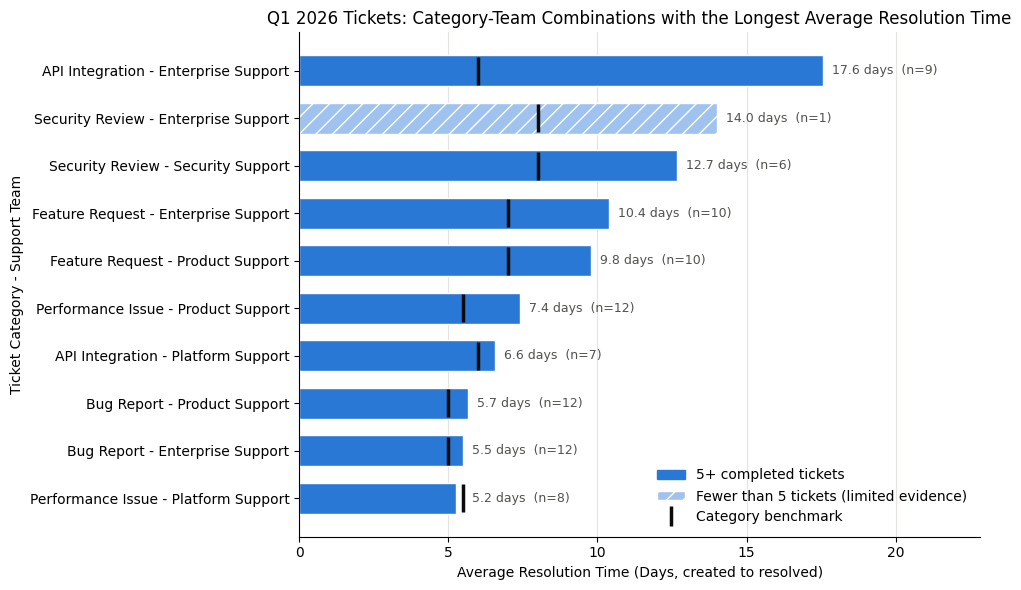

In [ ]:
top_resolution_df["category_team"] = (
    top_resolution_df["category_name"] + " - " + top_resolution_df["team_name"]
)

BLUE, LIGHT, INK, MUTED = "#2a78d6", "#9fc3ee", "#0b0b0b", "#52514e"

plt.figure(figsize=(10, 6))
colors = [LIGHT if small else BLUE for small in top_resolution_df["small_sample"]]
bars = plt.barh(
    top_resolution_df["category_team"],
    top_resolution_df["avg_resolution_days"],
    color=colors,
    edgecolor="white",
    height=0.65,
)
for bar, small in zip(bars, top_resolution_df["small_sample"]):
    if small:
        bar.set_hatch("//")
plt.scatter(top_resolution_df["benchmark_days"], top_resolution_df["category_team"],
            marker="|", s=400, linewidths=2.5, color=INK, zorder=3, label="Category benchmark (standard days)")

for bar, (_, row) in zip(bars, top_resolution_df.iterrows()):
    # Start the label after the bar or the benchmark marker, whichever is further right
    plt.text(max(bar.get_width(), row.benchmark_days) + 0.3, bar.get_y() + bar.get_height() / 2,
             f"{row.avg_resolution_days:.1f} days  (n={row.total_completed_tickets})",
             va="center", fontsize=9, color=MUTED)

plt.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color=BLUE, label=f"{SMALL_SAMPLE}+ completed tickets"),
    plt.Rectangle((0, 0), 1, 1, facecolor=LIGHT, hatch="//", edgecolor="white", label=f"Fewer than {SMALL_SAMPLE} tickets (limited evidence)"),
    plt.Line2D([0], [0], marker="|", color=INK, linestyle="none", markersize=14, markeredgewidth=2.5, label="Category benchmark"),
], loc="lower right", frameon=False)

plt.xlabel("Average Resolution Time (Days, created to resolved)")
plt.ylabel("Ticket Category - Support Team")
plt.title("Q1 2026 Tickets: Category-Team Combinations with the Longest Average Resolution Time")
plt.xlim(0, top_resolution_df["avg_resolution_days"].max() * 1.3)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.grid(axis="x", color="#e4e3df", linewidth=0.8)
plt.gca().set_axisbelow(True)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Step 11: Evaluate and Verify the Output (Verify)

Required checks first, then additional independent checks.

In [ ]:
# Required check 1: total completed tickets across all groups
resolution_df["total_completed_tickets"].sum()

np.int64(171)

In [ ]:
# Required check 2: range of average resolution times
resolution_df["avg_resolution_days"].min(), resolution_df["avg_resolution_days"].max()

(0.83, 17.56)

In [ ]:
# Required check 3: any negative averages (resolved before created)?
resolution_df[resolution_df["avg_resolution_days"] < 0]

,category_name,team_name,total_completed_tickets,avg_resolution_days,max_resolution_days,benchmark_days,small_sample,days_over_benchmark


In [ ]:
# Additional checks against the ticket-level rows
checks = {}

# Date filter: every included ticket was created in Q1 2026
checks["created dates all within Q1 2026"] = ticket_level_df["created_date"].between("2026-01-01", "2026-03-31").all()
print("Created date range:", ticket_level_df["created_date"].min(), "to", ticket_level_df["created_date"].max())

# Status filter: only Resolved / Closed
checks["only Resolved/Closed statuses"] = set(ticket_level_df["status"]) <= {"Resolved", "Closed"}

# No duplicate tickets (joins did not multiply rows)
checks["no duplicate ticket_ids"] = ticket_level_df["ticket_id"].is_unique

# Ticket totals agree: SQL groups vs ticket-level rows vs status count from Step 7
expected_total = (q1_status_df.set_index("status").loc[["Resolved", "Closed"], "tickets"].sum()
                  - missing_resolved_date_df.iloc[0, 0])
checks["ticket totals agree (SQL groups = ticket rows = cohort - missing dates)"] = (
    resolution_df["total_completed_tickets"].sum() == len(ticket_level_df) == expected_total)

# No negative or missing individual durations
checks["no negative ticket durations"] = (ticket_level_df["resolution_days"] >= 0).all()
checks["no missing values in results"] = resolution_df.isna().sum().sum() == 0

# Independent re-calculation in pandas matches every SQL average
pandas_avg = (ticket_level_df.groupby(["category_name", "team_name"])["resolution_days"]
              .agg(["count", "mean"]).round(2).reset_index())
compare = resolution_df.merge(pandas_avg, on=["category_name", "team_name"])
checks["pandas averages match SQL averages"] = (
    len(compare) == len(resolution_df)
    and (compare["mean"] == compare["avg_resolution_days"]).all()
    and (compare["count"] == compare["total_completed_tickets"]).all())

# Chart matches the DataFrame: same 10 rows, in the same order, with the same values
checks["chart shows the top 10 rows of resolution_df"] = (
    top_resolution_df["avg_resolution_days"].tolist() == resolution_df["avg_resolution_days"].head(10).tolist()
    and [b.get_width() for b in bars] == top_resolution_df["avg_resolution_days"].tolist())

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
assert all(checks.values()), "A verification check failed"

Created date range: 2026-01-01 to 2026-03-31
PASS  created dates all within Q1 2026
PASS  only Resolved/Closed statuses
PASS  no duplicate ticket_ids
PASS  ticket totals agree (SQL groups = ticket rows = cohort - missing dates)
PASS  no negative ticket durations
PASS  no missing values in results
PASS  pandas averages match SQL averages
PASS  chart shows the top 10 rows of resolution_df


In [ ]:
# Unusual values: the slowest individual tickets, and completed tickets with no status history
display(ticket_level_df.sort_values("resolution_days", ascending=False).head(5))
pd.read_sql_query("""
SELECT tk.ticket_id, tk.created_date, tk.resolved_date, tk.status
FROM tickets AS tk
WHERE tk.status IN ('Resolved', 'Closed')
  AND tk.created_date >= '2026-01-01' AND tk.created_date < '2026-04-01'
  AND tk.resolved_date IS NOT NULL
  AND tk.ticket_id NOT IN (SELECT ticket_id FROM ticket_events);
""", conn)

,ticket_id,category_name,team_name,created_date,resolved_date,status,priority,reopened_count,resolution_days
169,452,API Integration,Enterprise Support,2026-01-04,2026-03-20,Resolved,Medium,1,75.0
170,455,Feature Request,Enterprise Support,2026-01-20,2026-02-18,Resolved,Low,0,29.0
59,58,Feature Request,Product Support,2026-01-06,2026-01-23,Resolved,Low,0,17.0
77,124,API Integration,Enterprise Support,2026-01-24,2026-02-10,Resolved,Low,0,17.0
93,170,Security Review,Security Support,2026-03-02,2026-03-19,Resolved,Low,0,17.0


,ticket_id,created_date,resolved_date,status
0,453,2026-02-12,2026-02-25,Closed
1,452,2026-01-04,2026-03-20,Resolved
2,455,2026-01-20,2026-02-18,Resolved


### Verification Notes

| Check | Result |
|---|---|
| Did the database connection work? | ✅ Read-only connection opened; the required-table check passed after correcting `categories` → `ticket_categories`. |
| Did I inspect the database first? | ✅ Step 4 listed the tables, their columns, status values and date ranges before any analysis query. |
| Actual table and column names used? | ✅ `tickets`, `ticket_categories`, `teams`, and their real columns. No placeholders remain. |
| Correct joins? | ✅ `tickets.category_id = ticket_categories.category_id` and `tickets.team_id = teams.team_id`. Every ticket matches, and no rows are duplicated. |
| Date filter matches the assigned period? | ✅ Created dates run from 2026-01-01 to 2026-03-31. I used `>= '2026-01-01' AND < '2026-04-01'`. |
| Only Resolved or Closed tickets? | ✅ Only those two statuses appear. **1** Resolved ticket was excluded for a missing `resolved_date` (Step 7). **37** Q1 tickets are still Open (13), In Progress (17) or Escalated (7) and are not in any average. |
| Does the resolution-time calculation make sense? | ✅ No negative durations. Averages range from 0.83 to 17.56 days, and the pandas re-calculation matches SQL exactly. |
| Did the DataFrame load correctly? | ✅ 18 rows × 6 columns, correct types, no missing values. Totals agree: 172 completed − 1 missing date = **171** tickets. |
| Missing values, duplicates or unusual values? | ⚠️ No duplicates or negative values. **Ticket 452** (API Integration – Enterprise Support, 75 days) is an outlier that inflates its group's average. **3** completed tickets, including 452, have no rows in `ticket_events`. **2** groups have fewer than 5 tickets. |
| Does the chart match the DataFrame? | ✅ The bar lengths equal the top 10 `avg_resolution_days` values, in the same order. Small samples are marked. |
| Does the conclusion stay within what the data supports? | ✅ The conclusion below describes *where* resolution time is long, notes the outlier and small samples, and makes no claim about team performance or causes. |

## Step 12: Write a Supported Final Explanation

### Final Explanation

**Question.** Which support ticket categories took the longest to resolve for tickets created during Q1 2026 (January 1 – March 31), and does any team or category need closer review?

**Main finding.** **API Integration tickets handled by Enterprise Support** had the longest average resolution time: **17.6 days across 9 completed tickets**, against a 6-day standard for that category. At the category level, **Security Review (12.9 days), API Integration (12.8 days) and Feature Request (10.1 days)** took the longest, and all three ran above their benchmarks. Billing and Login Access tickets were resolved fastest, in about 1–2 days.

**Evidence.** A SQL query joined `tickets` to `ticket_categories` and `teams`. It kept the **171** tickets created in Q1 2026 with a `Resolved` or `Closed` status and a resolved date, then averaged `resolved_date − created_date` for each category–team combination. The results loaded into pandas with no missing or negative values. An independent pandas re-calculation from ticket-level rows matched every SQL average.

**Limitation.** The top result is sensitive to one ticket: **ticket 452 took 75 days**. Without it, API Integration – Enterprise Support averages **10.4 days**. That is still about 1.7× the benchmark and above Platform Support's 6.6 days on the same category, but it rests on only 8–9 tickets. The averages also cover only completed tickets. **1** completed ticket was excluded for a missing resolved date, and **37** Q1 tickets are still open, so the slowest cases may not be counted yet. Enterprise Support's higher overall average mostly reflects its mix of complex categories: on Bug Report and Feature Request tickets it performs similarly to other teams. This data does not show that any team is underperforming.

**Recommended next step.** Review the **Enterprise Support API Integration tickets**, starting with ticket 452 (reopened once, low satisfaction score, no status history in `ticket_events`). Check priority, customer tier and time spent waiting on the customer. Then repeat the analysis once the 37 open Q1 tickets close, to see whether the pattern holds.

## Step 13: Reflect on the Workflow

### Reflection

**What was the most important step in making my result trustworthy?**
The most important step was the verification at the ticket level. The SQL average said API Integration – Enterprise Support was the slowest group, but looking at the individual tickets showed one 75-day ticket inflating that number. Without that check I would have reported a 17.6-day problem that is closer to 10 days for typical tickets.

**What issue did I need to check, debug or refine?**
I seen two things in the provided code would have failed. The required-table check named `categories`, but the real table is `ticket_categories`. And the practice query had a `#` comment inside the SQL, which SQLite doesn't accept. Inspecting the database first (Step 4) made the first problem obvious. I also changed the date filter to the `>= ... < '2026-04-01'` form.

**How did Identify → Assemble → Execute → Verify help?**
Identify made me define "longest to resolve" and decide up front which claims to avoid, which shaped the whole analysis. Assemble (inspection and the query planning checklist) caught the table-name mismatch before it caused wrong results. Execute produced the numbers, and Verify told me how much to trust them: the outlier, the small samples and the open tickets.

**How could this workflow apply in other contexts?**
- **Cybersecurity:** average time-to-remediate vulnerabilities by severity and team.
- **Software engineering:** pull-request review time or bug fix time by component.
- **Business intelligence:** order fulfilment time by region.
- **AI-supported data preparation:** checking AI-generated SQL against the real schema before trusting its output.

The pattern is the same each time: query with a calculated duration, load into pandas, check outliers and sample sizes, and write a careful conclusion.

**What would I improve if I repeated this analysis?**
I would report medians alongside means in the main table and chart, segment by priority, and treat still-open tickets with a survival-style approach (time open so far) instead of excluding them. I would also use `ticket_events` to separate active work time from waiting time.

**What cloud constraint did I encounter, and how did I manage it?**
Files uploaded directly to the Colab runtime are deleted when the runtime resets. I stored `support_operations.db` in Google Drive and mount Drive in the connection cell, so after a reset I only rerun the notebook. My data stays in storage, separate from the temporary compute.

## Cloud Evidence

| Item | Evidence |
|---|---|
| **Platform choice** | Google Colab |
| **How and where the database file was stored** | Uploaded `support_operations.db` to Google Drive (`MyDrive/support_operations.db`). The notebook mounts Drive and connects read-only from that path, so the file persists across runtime resets. |
| **Ran top to bottom after a restart** | Used **Runtime → Restart session and run all**. Every cell ran without errors; the run record below shows the Colab platform and the Drive database path. |
| **Cloud constraint encountered and managed** | Colab runtime files are temporary. Storing the database in Drive and mounting it at the top of the notebook means a reset only requires rerunning, not re-uploading. |

The cell below records the environment each time the notebook runs, which serves as evidence of a full top-to-bottom run.

In [ ]:
import datetime
import platform

print(f"Run completed:    {datetime.datetime.now():%Y-%m-%d %H:%M:%S}")
print(f"Platform:         {'Google Colab' if IN_COLAB else 'Local / other Jupyter'} ({platform.system()})")
print(f"Python:           {platform.python_version()} | pandas {pd.__version__}")
print(f"Database file:    {db_path} ({db_path.stat().st_size:,} bytes)")
print(f"Verification:     {sum(checks.values())}/{len(checks)} checks passed")

Run completed:    2026-10-23 15:18:54
Platform:         Google Colab (Linux)
Python:           3.13.16 | pandas 2.2.3
Database file:    /content/drive/MyDrive/support_operations.db (204,800 bytes)
Verification:     8/8 checks passed


## Close the Database Connection

In [ ]:
conn.close()
print("Database connection closed.")

Database connection closed.
